# Complete Engineering Unsymmetric3D

Run all cells in your OneSimulation environment. The recorded output below was generated by executing this code. The spatial view uses the solved forces, eigenvectors or stress tensor.

Centroid [mm]: [25. 20.]
Stress-plane coefficients [MPa/mm]: [1.234286 2.502857]
Principal area moments [mm^4]: [ 291666.667 1166666.667]
Stress at (80,10) mm [MPa]: 42.857143


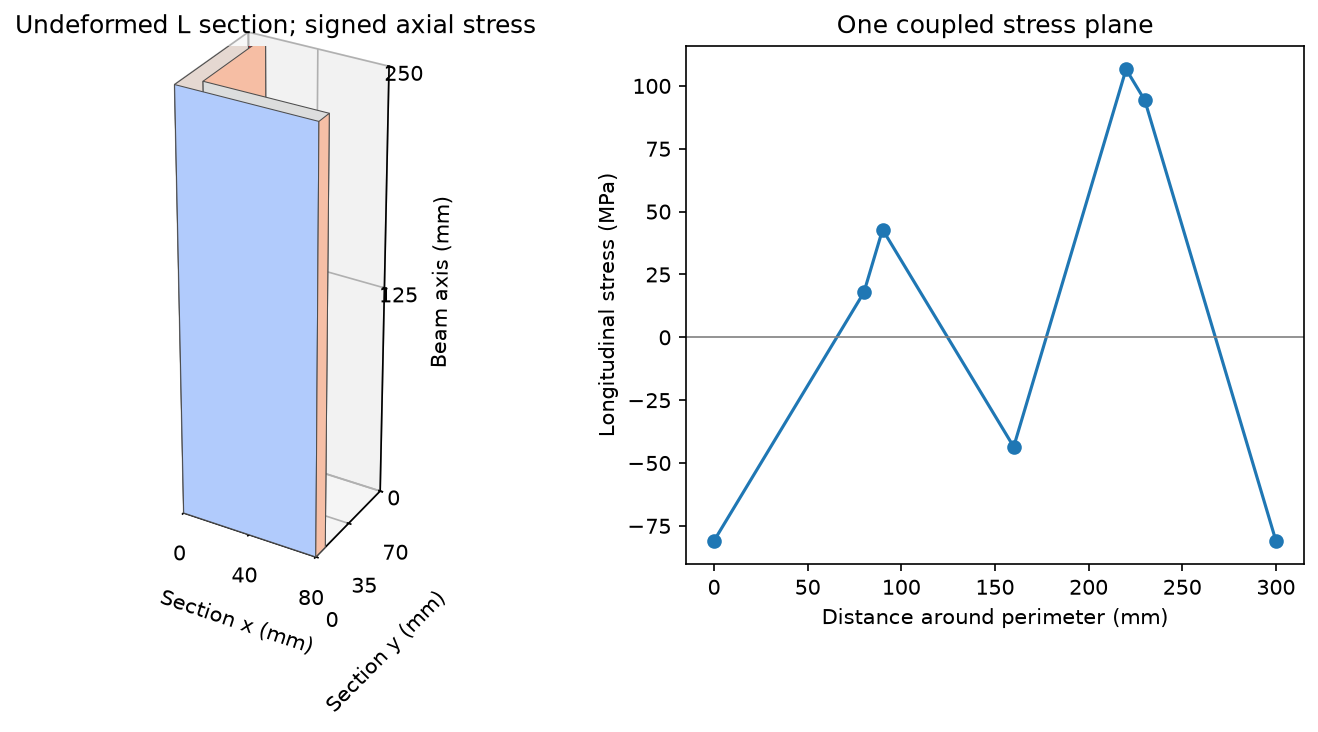

In [1]:
"""Resolve a biaxial moment with OneSimulation and inspect a 3D prismatic L section."""
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from onesim.numerics.linear.matrices.dense_linear_algebra import solve_dense, symmetric_eigensystem

# mm, N, MPa. Two nonoverlapping rectangles; moments follow the chapter signs.
rectangles = [(800., 40., 5., 80., 10.), (600., 5., 40., 10., 60.)]
area = sum(row[0] for row in rectangles)
centroid = np.array([sum(A*x for A,x,y,w,h in rectangles),
                     sum(A*y for A,x,y,w,h in rectangles)])/area
Ixx = sum(A*h*h/12+A*(y-centroid[1])**2 for A,x,y,w,h in rectangles)
Iyy = sum(A*w*w/12+A*(x-centroid[0])**2 for A,x,y,w,h in rectangles)
Ixy = sum(A*(x-centroid[0])*(y-centroid[1]) for A,x,y,w,h in rectangles)
matrix = np.array([[Iyy,Ixy],[Ixy,Ixx]])
Mx, My = 1e6, 0.0  # N mm; change these two inputs as in the live view
coefficients = solve_dense(matrix,np.array([-My,Mx]))
values, axes = symmetric_eigensystem(matrix)
assert np.allclose(matrix@coefficients,[-My,Mx])
assert np.allclose(axes@np.diag(values)@axes.T,matrix)
outline = np.array([[0,0],[80,0],[80,10],[10,10],[10,70],[0,70],[0,0]],dtype=float)
stress = (outline-centroid)@coefficients
print('Centroid [mm]:',centroid)
print('Stress-plane coefficients [MPa/mm]:',np.round(coefficients,6))
print('Principal area moments [mm^4]:',np.round(values,3))
print('Stress at (80,10) mm [MPa]:',round(stress[2],6))

fig = plt.figure(figsize=(9,4.2),layout='constrained')
ax = fig.add_subplot(121,projection='3d')
faces=[];colors=[]
scale=max(abs(stress))
for i in range(len(outline)-1):
    p,q=outline[i:i+2]
    faces.append([[*p,0],[*q,0],[*q,250],[*p,250]])
    colors.append(plt.cm.coolwarm(.5+.5*(stress[i]+stress[i+1])/2/scale))
ax.add_collection3d(Poly3DCollection(faces,facecolors=colors,edgecolors='0.3',linewidths=.5))
ax.set(xlim=(0,80),ylim=(0,70),zlim=(0,250),xlabel='Section x (mm)',ylabel='Section y (mm)',zlabel='Beam axis (mm)',title='Undeformed L section; signed axial stress')
ax.set(xticks=[0,40,80], yticks=[0,35,70], zticks=[0,125,250])
ax.tick_params(axis='x', pad=1)
ax.tick_params(axis='y', pad=8)
ax.tick_params(axis='z', pad=1)
ax.zaxis.labelpad = 16
ax.yaxis.labelpad = 18
ax.set_box_aspect((80,70,250))
ax2=fig.add_subplot(122)
arc=np.r_[0,np.cumsum(np.linalg.norm(np.diff(outline,axis=0),axis=1))]
ax2.plot(arc,stress,'o-')
ax2.axhline(0,color='0.5',lw=.8)
ax2.set(xlabel='Distance around perimeter (mm)',ylabel='Longitudinal stress (MPa)',title='One coupled stress plane')
fig.savefig('complete-engineering-unsymmetric3d.png',dpi=170)
plt.show()
